In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pickle

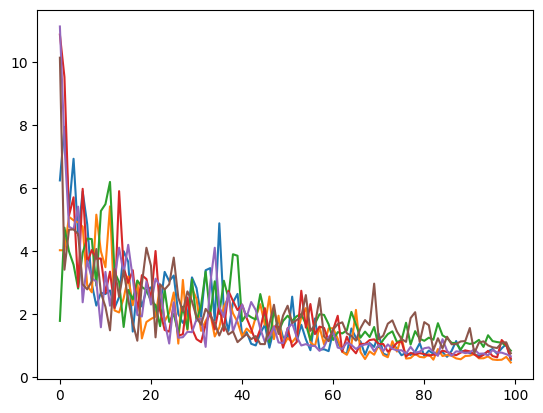

In [28]:
random_directory_path = "C:/Users/henry/Desktop/UCL/ExtraQNLPWork/qnlp_lorenz_etal_2021_resources/code/rp_runs/noise_random/"
pretrained_directory_path = "C:/Users/henry/Desktop/UCL/ExtraQNLPWork/qnlp_lorenz_etal_2021_resources/code/rp_runs/noise_pretrained/"

def get_training_path(directory_path, niter=100):
    files = [directory_path+ i for i in os.listdir(directory_path)]

    cost_histories = np.zeros(shape=(len(files), niter))
    error_train_histories = np.zeros(shape=(len(files), niter))

    iters_selected = np.zeros(shape=(len(files), 11))
    error_test_histories = np.zeros(shape=(len(files), 11))

    for f_index, file in enumerate(files):
        with open(file, 'rb') as file:
            data = pickle.load(file)
        if len(data['error_history']) != 100:
            print(file + " Has less than 100 iterations!")
            break

        cost_histories[f_index, :] = data['func_history']
        error_train_histories[f_index, :] = data['error_history'] 
        error_test_histories[f_index, :] = data['test_error_list']
        iters_selected[f_index, :] = data['iters_selected']

        assert(len(data['test_error_list']) == len(data['iters_selected']))
        assert(len(data['func_history']) == len(data['error_history']))

    cost_history_mean = cost_histories.mean(0)
    error_train_history_mean = error_train_histories.mean(0)

    error_test_history_mean = error_test_histories.mean(0)
    return cost_history_mean, error_train_history_mean, error_test_history_mean

random_cost, random_train, random_test = get_training_path(random_directory_path)
pretrained_cost, pretrained_train, pretrained_test = get_training_path(pretrained_directory_path)

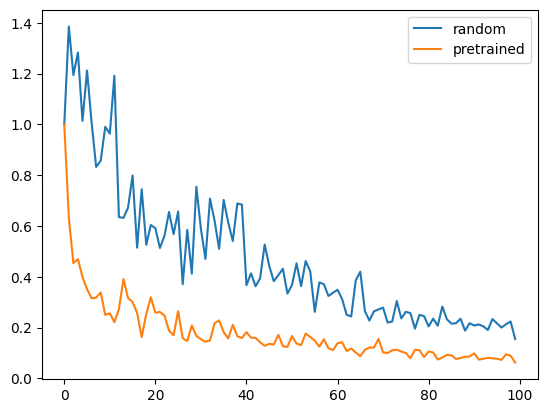

In [22]:
plt.plot(random_cost/random_cost[0], label='random')
plt.plot(pretrained_cost/pretrained_cost[0], label='pretrained')
plt.legend()

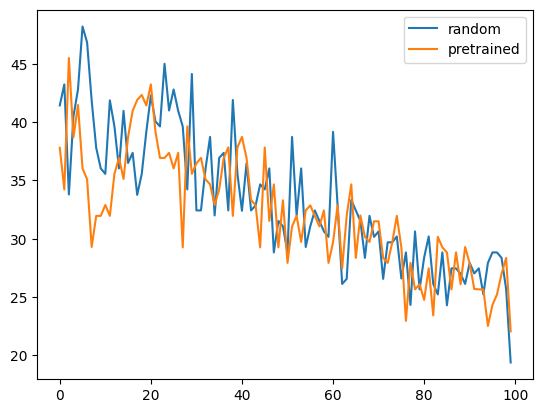

In [23]:
plt.plot(random_train, label='random')
plt.plot(pretrained_train, label='pretrained')
plt.legend()

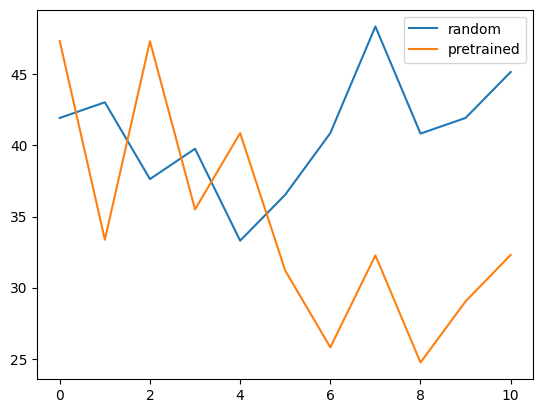

In [24]:
plt.plot(random_test, label='random')
plt.plot(pretrained_test, label='pretrained')
plt.legend()

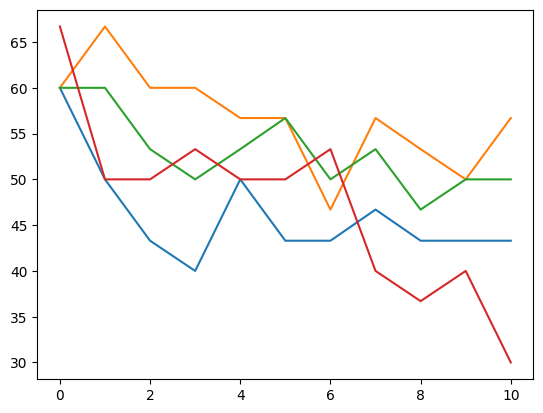

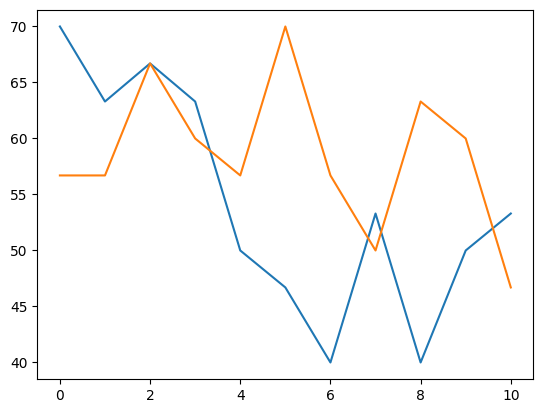

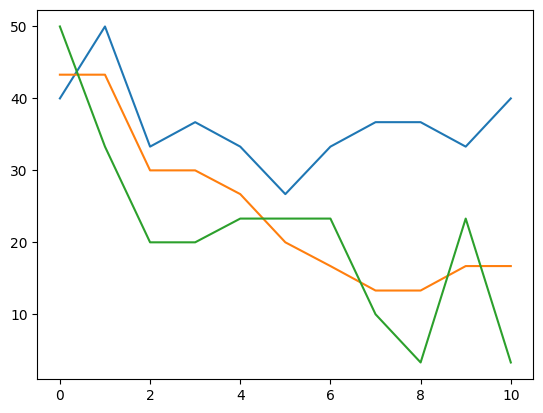

In [55]:
random_directory_path = "C:/Users/henry/Desktop/UCL/ExtraQNLPWork/qnlp_lorenz_etal_2021_resources/code/mc_runs/noise_pretrained_unscaled/"
pretrained_directory_path = "C:/Users/henry/Desktop/UCL/ExtraQNLPWork/qnlp_lorenz_etal_2021_resources/code/mc_runs/noise_pretrained/"
pi_path = "C:/Users/henry/Desktop/UCL/ExtraQNLPWork/qnlp_lorenz_etal_2021_resources/code/mc_runs/noise_pretrained_twopi_scale/"

def get_training_path(directory_path, niter=100):
    files = [directory_path+ i for i in os.listdir(directory_path)]

    cost_histories = np.zeros(shape=(len(files), niter))
    error_train_histories = np.zeros(shape=(len(files), niter))

    iters_selected = np.zeros(shape=(len(files), 11))
    error_test_histories = np.zeros(shape=(len(files), 11))

    for f_index, file in enumerate(files):
        with open(file, 'rb') as file:
            data = pickle.load(file)
        if len(data['error_history']) == 100:

            cost_histories[f_index, :] = data['func_history']
            error_train_histories[f_index, :] = data['error_history']
            error_test_histories[f_index, :] = data['test_error_list']
            iters_selected[f_index, :] = data['iters_selected']
            plt.plot(data['test_error_list'])

            assert(len(data['test_error_list']) == len(data['iters_selected']))
            assert(len(data['func_history']) == len(data['error_history']))

    cost_history_mean = cost_histories.mean(0)
    error_train_history_mean = error_train_histories.mean(0)

    error_test_history_mean = error_test_histories.mean(0)
    plt.show()
    return cost_history_mean, error_train_history_mean, error_test_history_mean

random_cost, random_train, random_test = get_training_path(random_directory_path)
pretrained_cost, pretrained_train, pretrained_test = get_training_path(pretrained_directory_path)
pretrained_cost, pretrained_train, pretrained_test = get_training_path(pi_path)

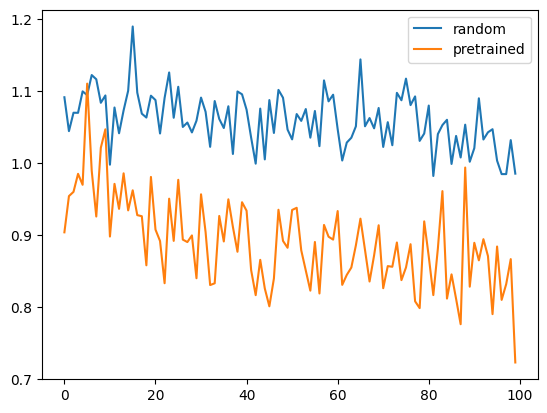

In [46]:
plt.plot(random_cost, label='random')
plt.plot(pretrained_cost, label='pretrained')
plt.legend()

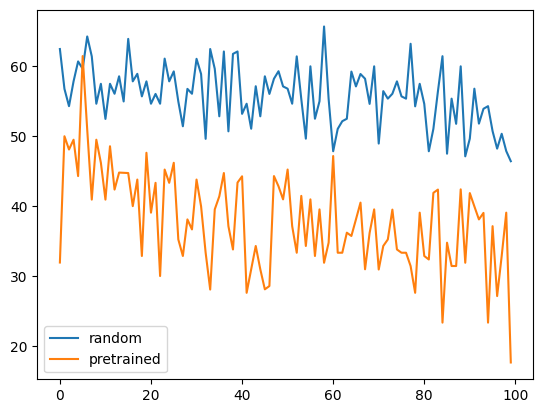

In [47]:
plt.plot(random_train, label='random')
plt.plot(pretrained_train, label='pretrained')
plt.legend()

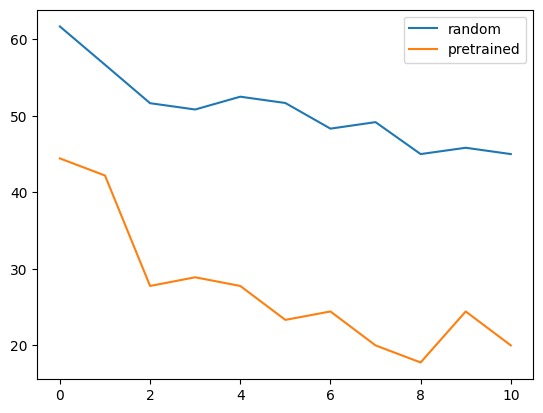

In [48]:
plt.plot(random_test, label='random')
plt.plot(pretrained_test, label='pretrained')
plt.legend()